In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

df = pd.read_csv("noisy_curvefit_data.csv", comment="#")

In [28]:
print(df.shape)
# There are 100 rows and 6 columns

display(df.head())
display(df.tail())

print(df.columns)

(100, 6)


,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
0,-1.000000,11.624419,8.296963,12.201067,7.811725,3.155566
1,-0.929293,10.377466,9.674440,12.198084,8.275006,7.518855
2,-0.858586,10.585100,9.251983,13.186565,12.926586,9.963630
3,-0.787879,10.913928,7.786344,12.552304,11.832379,9.625801
4,-0.717172,8.640287,8.551869,4.741432,8.790834,6.624113


,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
95,5.717172,-1.411918,0.822231,-2.027132,-1.825106,2.746147
96,5.787879,0.344879,-1.718956,2.747559,-6.803779,-5.137472
97,5.858586,0.307133,0.353528,0.967976,5.461567,-0.905616
98,5.929293,0.048657,0.159961,2.482130,-0.414616,-4.334548
99,6.000000,-0.193438,-2.244792,1.930035,4.992414,-6.872850


Index(['x', 'y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5'], dtype='str')


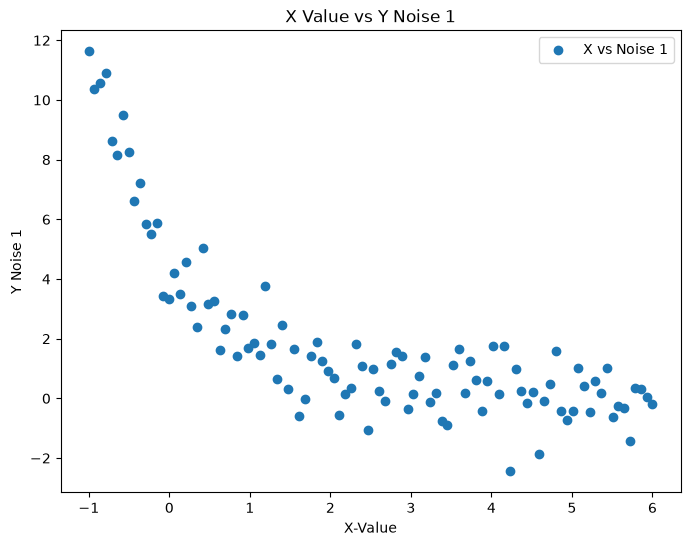

In [42]:
plt.figure(figsize=(8,6)) # Creating the figure

plt.scatter(x = df["x"], y = df["y_noise_1"], label = "X vs Noise 1")
plt.legend() # Creates a legend

# Titles and labels
plt.title("X Value vs Y Noise 1")
plt.xlabel("X-Value")
plt.ylabel("Y Noise 1")

plt.show()

Fit: y = 4.71 * e^(-0.92 * x


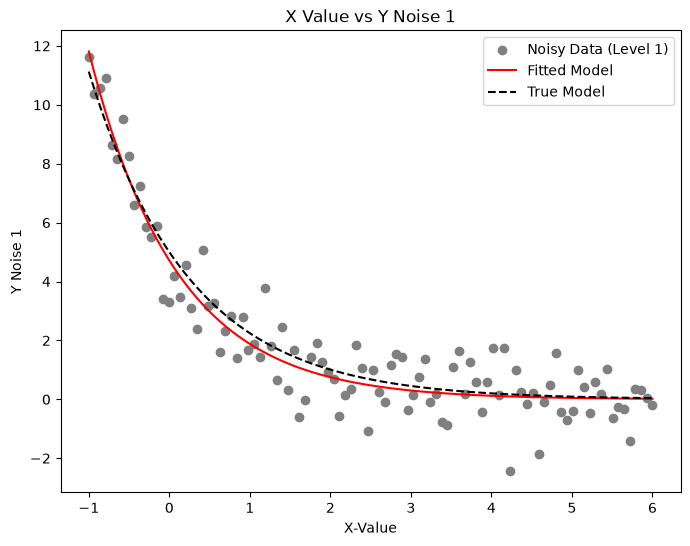

In [46]:
def model(x, A, k):
    return A * np.exp(-k * x)

x = df["x"]
y_noise_1 = df["y_noise_1"]

p0 = [1, 1]
popt, pcov = curve_fit(model, x, y_noise_1, p0=p0)

A_fit, k_fit = popt

print(f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x")

residuals = y_noise_1 - model(x, A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(x) - len(popt)
chi2_reduced = chi2 / dof

plt.figure(figsize=(8,6)) # Creating the figure

plt.scatter(x, y_noise_1, color="gray", label="Noisy Data (Level 1)")
plt.plot(x, model(x, A_fit, k_fit), color="red", label="Fitted Model")
plt.plot(x, model(x, 5, 0.8), color="black", linestyle="--", label="True Model")


plt.legend() # Creates a legend

# Titles and labels
plt.title("X Value vs Y Noise 1")
plt.xlabel("X-Value")
plt.ylabel("Y Noise 1")

plt.show()

In [49]:
def fit_model(x,y):
    popt, pcov = curve_fit(model, x, y, p0=p0)
    A_fit, k_fit = popt
    
    residuals = y - model(x, A_fit, k_fit)
    chi2 = np.sum(residuals**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof

    return popt, chi2_reduced

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

noise_columns = [df[y_noise_2], df[y_noise_3], df[y_noise_4], df[y_noise_5]]

for i, col in enumerate(noise_columns):
    row = i // 2
    col_idx = i % 2
    ax = axes[row, col_idx]

    popt, chi2_reduced = fit_model(df["x"], y_data)
    A_fit, k_fit = popt

    ax.scatter(df["x"], y_data, color="gray", label="Noisy Data")